In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
sns.set_theme(style="whitegrid")

## Task 1

In [3]:
df=pd.read_csv(r"D:\Python\Module5_Practices live class\social_media_engagement_5000.csv")
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [5]:
df.dtypes

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object

In [6]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [7]:
df['posted_at'] = pd.to_datetime(df['posted_at'])

C:\Users\USER\AppData\Local\Temp\ipykernel_17800\1302919506.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['posted_at'] = pd.to_datetime(df['posted_at'])


In [8]:
df['posted_at'].dtype

dtype('<M8[ns]')

In [9]:
likes_array = df['likes'].to_numpy(na_value=0)
comments_array = df['comments'].to_numpy(na_value=0)

In [10]:
total_likes_np = np.sum(likes_array)
mean_comments_np = np.mean(comments_array)

## Task 2

In [11]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [12]:
for col in ['likes', 'comments', 'shares', 'age']:
    df[col] = df[col].fillna(df[col].median())

In [13]:
for col in ['gender', 'sentiment']:
    df[col] = df[col].fillna(df[col].mode()[0])

In [14]:
df.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

In [15]:
print(f"Duplicates before removal: {df.duplicated().sum()}")
df = df.drop_duplicates().reset_index(drop=True)

Duplicates before removal: 0


In [16]:
df['likes'] = df['likes'].abs()
df['comments'] = df['comments'].abs()
df['shares'] = df['shares'].abs()

In [17]:
df['gender'] = df['gender'].str.capitalize().str.strip()
df['sentiment'] = df['sentiment'].str.lower().str.strip()

In [18]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [20]:
df['hashtag_count'] = df['hashtags'].astype(str).apply(lambda x: len(x.split()) if x.strip() != '' else 0)
df['sentiment'].value_counts()

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

## Task 3

In [21]:
print(f"Shape: {df.shape}")
df.columns

Shape: (5000, 20)


Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')

In [22]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [23]:
df.dtypes

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
hashtag_count                int64
dtype: object

In [24]:
print(df['post_type'].value_counts())
print(df['country'].value_counts())

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64


numeric_cols = df.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()
corr_matrix

In [25]:
df.groupby('post_type')['likes'].mean()

post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64

In [26]:
df.groupby('country')['impression_count'].sum()

country
Australia    23834767
Brazil       24793360
Canada       24984716
France       25656926
Germany      23816649
India        28067377
Japan        23418816
UAE          24610992
UK           25201861
USA          25683200
Name: impression_count, dtype: int64

## Task 4

In [27]:
df['engagement_score'] = (df['likes'] * 1 + df['comments'] * 2 + df['shares'] * 3) / (df['follower_count'] + 1)

In [28]:
df['log_likes'] = np.log1p(df['likes'])
df['log_impressions'] = np.log1p(df['impression_count'])

df[['engagement_score', 'log_likes', 'log_impressions']].head()

,engagement_score,log_likes,log_impressions
0,0.136906,8.855378,10.706632
1,3.753018,9.371694,11.292491
2,0.016770,8.489411,10.711280
3,0.022205,8.585039,11.162744
4,0.057437,9.448018,8.702843


In [29]:
df.groupby(['post_type', 'sentiment'])['engagement_rate'].agg(['mean', 'median', 'count'])

mean    median  count
post_type sentiment                           
image     negative   0.713925  0.262422    221
          neutral    1.176670  0.257184    387
          positive   0.788296  0.271064    639
reel      negative   1.280989  0.255600    255
          neutral    0.580533  0.264156    388
          positive   0.707422  0.236310    640
text      negative   1.084785  0.247722    234
          neutral    0.726697  0.236407    397
          positive   1.275286  0.267048    614
video     negative   1.034708  0.247330    250
          neutral    1.533522  0.250818    355
          positive   0.922290  0.243542    620

## Task 5

In [30]:
metrics = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate', 'follower_count']

stats_summary = pd.DataFrame({
    'Mean': df[metrics].mean(),
    'Median': df[metrics].median(),
    'Std Dev': df[metrics].std(),
    'Variance': df[metrics].var(),
    'Skewness': df[metrics].skew()
})

stats_summary

,Mean,Median,Std Dev,Variance,Skewness
likes,10106.997400,10105.500000,5702.293017,3.251615e+07,-0.006894
comments,1502.039800,1497.000000,856.393312,7.334095e+05,0.003802
shares,1002.910600,1012.000000,570.855200,3.258757e+05,-0.014654
watch_time_sec,4014.503200,4034.500000,2308.096459,5.327309e+06,-0.018196
engagement_rate,0.964356,0.253896,5.318029,2.828143e+01,18.781271
follower_count,393698.224800,388982.000000,230927.884535,5.332769e+10,0.041118


## Task 6

## 1. Scatter Plot: Likes vs Impressions

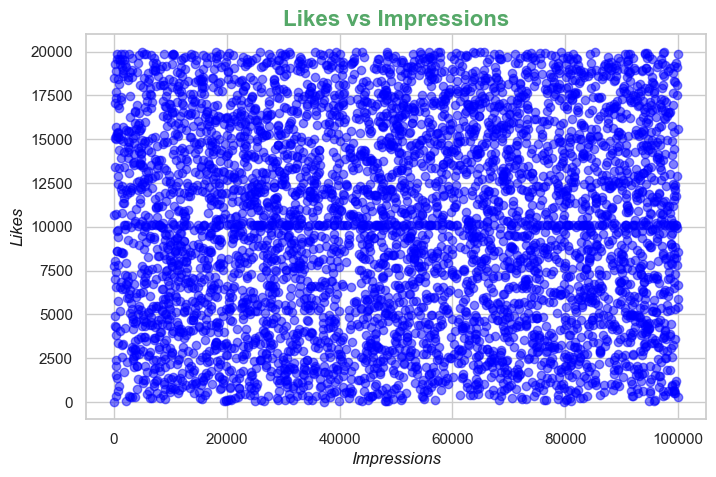

In [31]:
plt.figure(figsize=(8, 5))
plt.scatter(df['impression_count'], df['likes'], color='blue', alpha=0.5)
plt.title("Likes vs Impressions", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Impressions", color='k', fontsize='12', fontstyle='italic')
plt.ylabel("Likes", color='k', fontsize='12', fontstyle='italic')
plt.grid(True)
plt.show()

## 2. Line Chart: Daily Engagement Trend

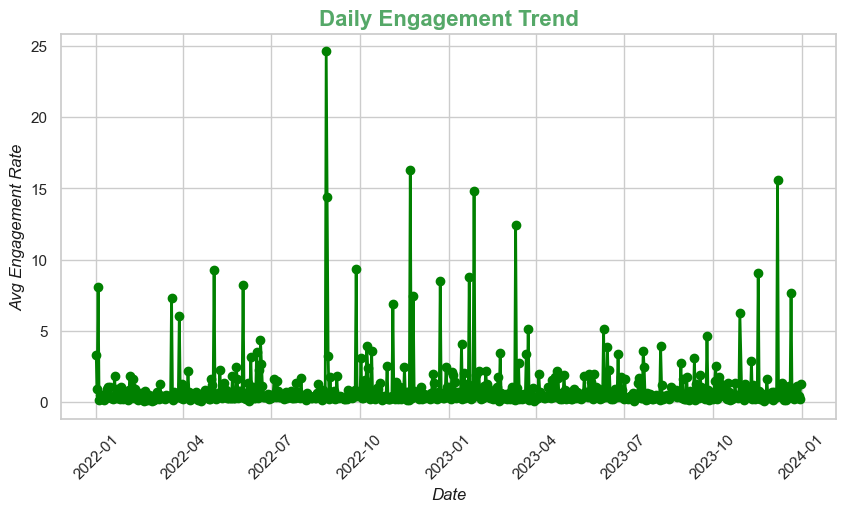

In [32]:
daily_trend = df.groupby(df['posted_at'].dt.date)['engagement_rate'].mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_trend.index, daily_trend.values, color='green', marker='o', linestyle='-', linewidth=2)
plt.title("Daily Engagement Trend", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Date", color='k', fontsize='12', fontstyle='italic')
plt.ylabel("Avg Engagement Rate", color='k', fontsize='12', fontstyle='italic')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

## 3. Bar Chart: Posts by Category

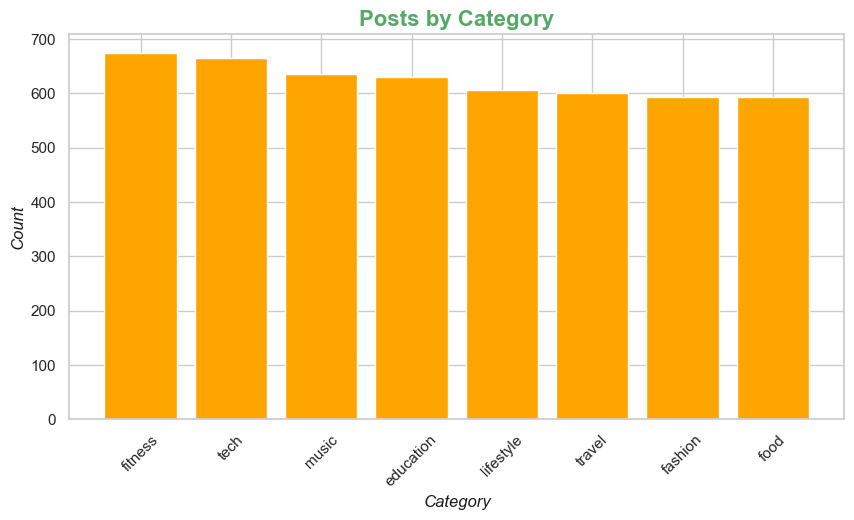

In [33]:
category_counts = df['post_category'].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(category_counts.index, category_counts.values, color='orange')
plt.title("Posts by Category", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Category", color='k', fontsize='12', fontstyle='italic')
plt.ylabel("Count", color='k', fontsize='12', fontstyle='italic')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

## 4. Pie Chart: Gender Distribution

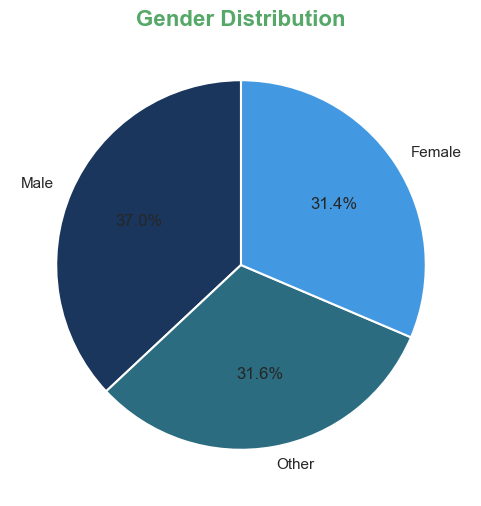

In [34]:
gender_counts = df['gender'].value_counts()
colors = ['#1A365D', '#2B6C80', '#4299E1']

plt.figure(figsize=(6, 6))
plt.pie(gender_counts.values, labels=gender_counts.index, colors=colors, autopct='%1.1f%%', 
        startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
plt.title("Gender Distribution", color='g', fontsize='16', fontweight='bold')
plt.show()

## 5. Histogram: Age

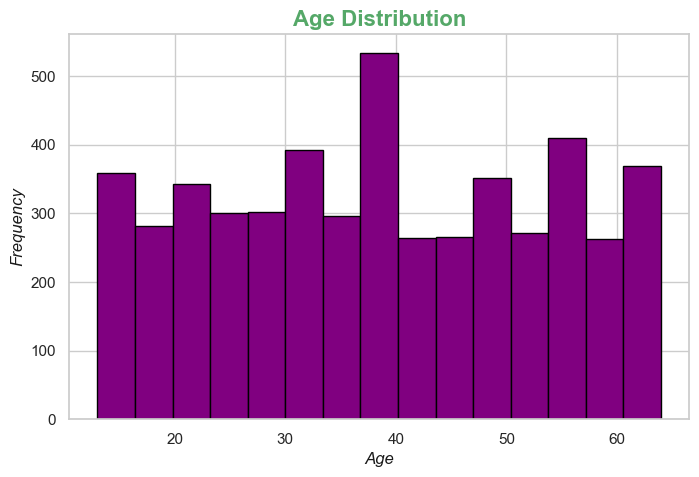

In [35]:
plt.figure(figsize=(8, 5))
plt.hist(df['age'].dropna(), bins=15, color='purple', edgecolor='black')
plt.title("Age Distribution", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Age", color='k', fontsize='12', fontstyle='italic')
plt.ylabel("Frequency", color='k', fontsize='12', fontstyle='italic')
plt.grid(True)
plt.show()

## 6. Box Plot: Engagement Rate

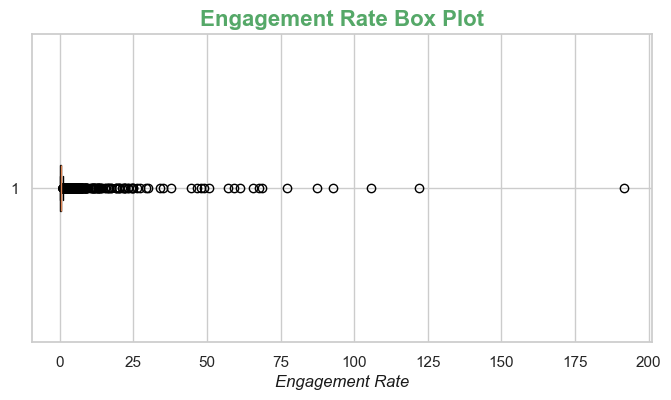

In [36]:
plt.figure(figsize=(8, 4))
plt.boxplot(df['engagement_rate'].dropna(), vert=False, patch_artist=True)
plt.title("Engagement Rate Box Plot", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Engagement Rate", color='k', fontsize='12', fontstyle='italic')
plt.grid(True)
plt.show()

# Seaborn Plots

## 1.Count Plot: Post Type

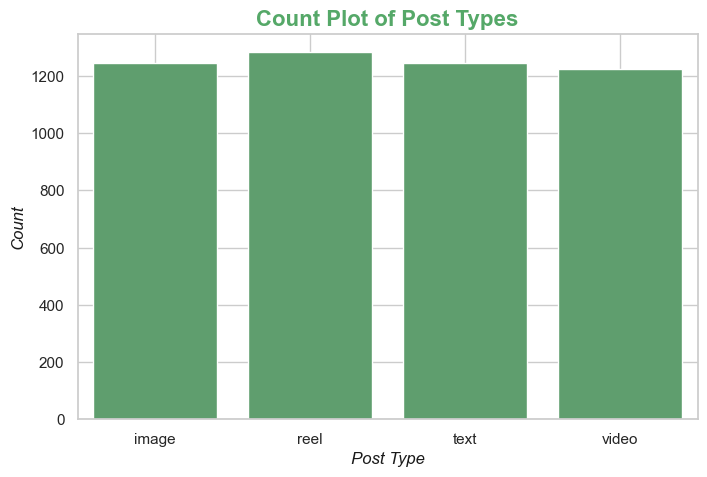

In [37]:
plt.figure(figsize=(8, 5))
sns.countplot(x=df['post_type'], color='g')
plt.title("Count Plot of Post Types", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Post Type", color='k', fontsize='12', fontstyle='italic')
plt.ylabel("Count", color='k', fontsize='12', fontstyle='italic')
plt.grid(True)
plt.show()

## 2. Bar Plot: Average Likes by Category

C:\Users\USER\AppData\Local\Temp\ipykernel_17800\2006974093.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df['post_category'], y=df['likes'], estimator=lambda x: sum(x) / len(x), palette='viridis')


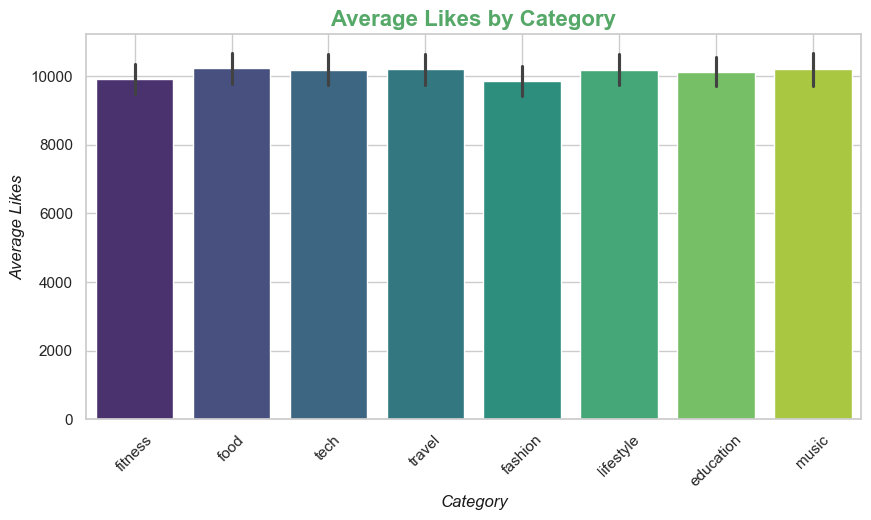

In [38]:
plt.figure(figsize=(10, 5))
sns.barplot(x=df['post_category'], y=df['likes'], estimator=lambda x: sum(x) / len(x), palette='viridis')
plt.title("Average Likes by Category", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Category", color='k', fontsize='12', fontstyle='italic')
plt.ylabel("Average Likes", color='k', fontsize='12', fontstyle='italic')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

## 3. Violin Plot: Followers vs Sentiment

C:\Users\USER\AppData\Local\Temp\ipykernel_17800\831011536.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=df['sentiment'], y=df['follower_count'], palette='muted')


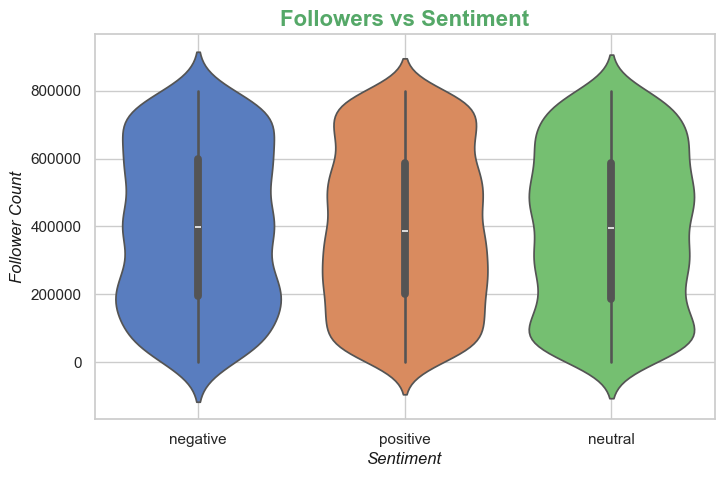

In [39]:
plt.figure(figsize=(8, 5))
sns.violinplot(x=df['sentiment'], y=df['follower_count'], palette='muted')
plt.title("Followers vs Sentiment", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Sentiment", color='k', fontsize='12', fontstyle='italic')
plt.ylabel("Follower Count", color='k', fontsize='12', fontstyle='italic')
plt.grid(True)
plt.show()

## 4. Heatmap: Correlation Matrix

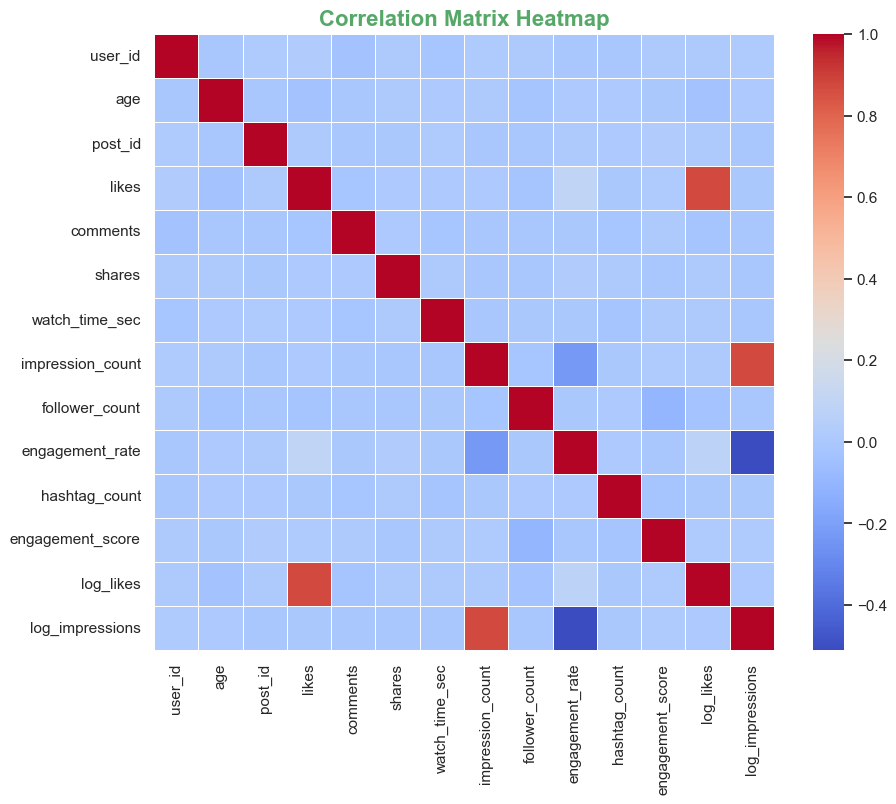

In [40]:
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Matrix Heatmap", color='g', fontsize='16', fontweight='bold')
plt.show()

## 5.Pair Plot: Numeric Features

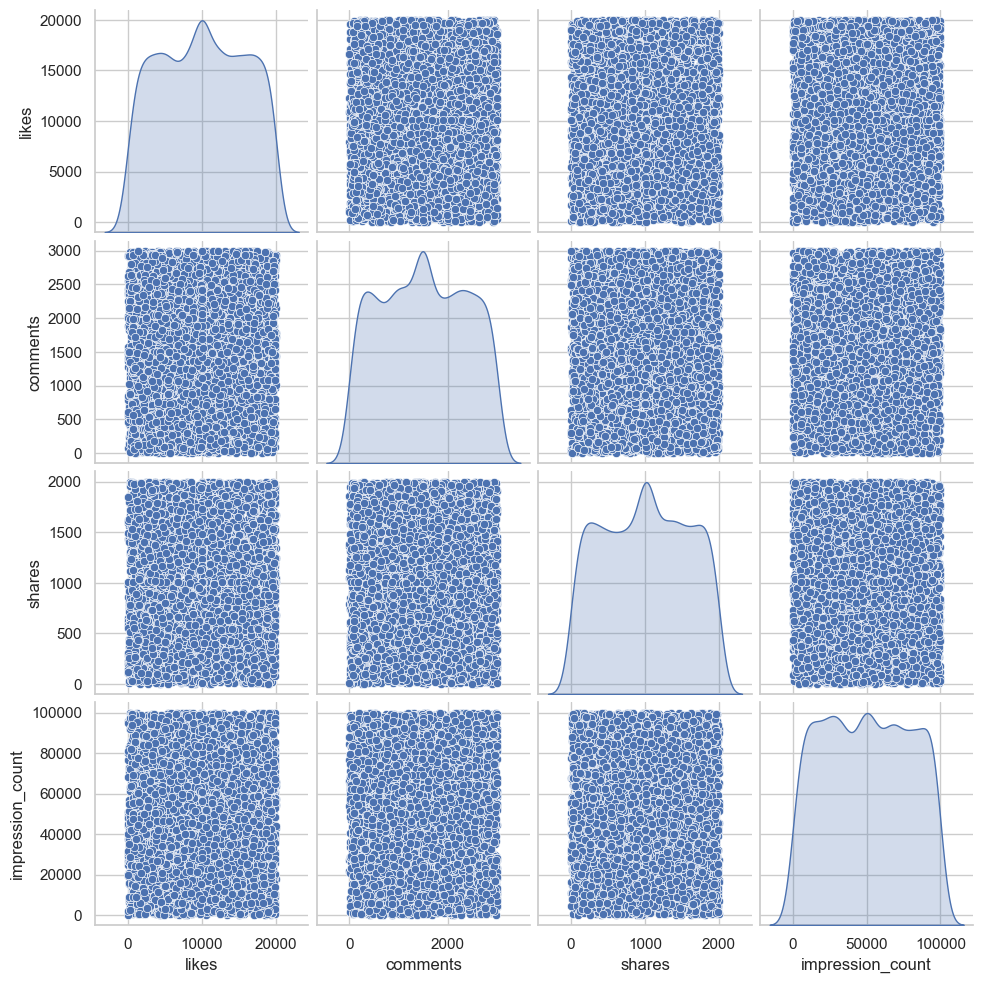

In [41]:
sns.pairplot(df[['likes', 'comments', 'shares', 'impression_count']], diag_kind='kde')
plt.show()

## 6. Swarm Plot: Engagement Rate vs Device Type

C:\Users\USER\AppData\Local\Temp\ipykernel_17800\281145710.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.prune = sns.swarmplot(x=df.sample(500, random_state=42)['device_type'],
C:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 75.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 76.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 80.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Us

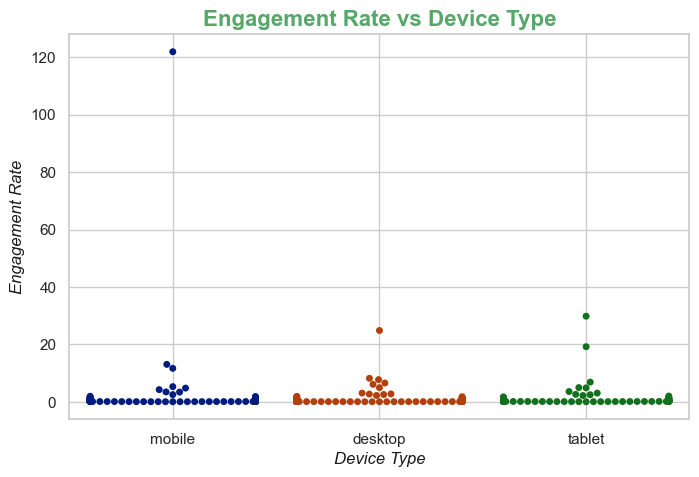

In [42]:
plt.figure(figsize=(8, 5))
sns.prune = sns.swarmplot(x=df.sample(500, random_state=42)['device_type'], 
                          y=df.sample(500, random_state=42)['engagement_rate'], 
                          palette='dark')
plt.title("Engagement Rate vs Device Type", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Device Type", color='k', fontsize='12', fontstyle='italic')
plt.ylabel("Engagement Rate", color='k', fontsize='12', fontstyle='italic')
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.swarmplot(x=df['device_type'], y=df['engagement_rate'], palette='dark')
plt.title("Engagement Rate vs Device Type", color='g', fontsize='16', fontweight='bold')
plt.xlabel("Device Type", color='k', fontsize='12', fontstyle='italic')
plt.ylabel("Engagement Rate", color='k', fontsize='12', fontstyle='italic')
plt.grid(True)
plt.show()

## Plotly Interactive Chart
* Interactive Scatter Plot

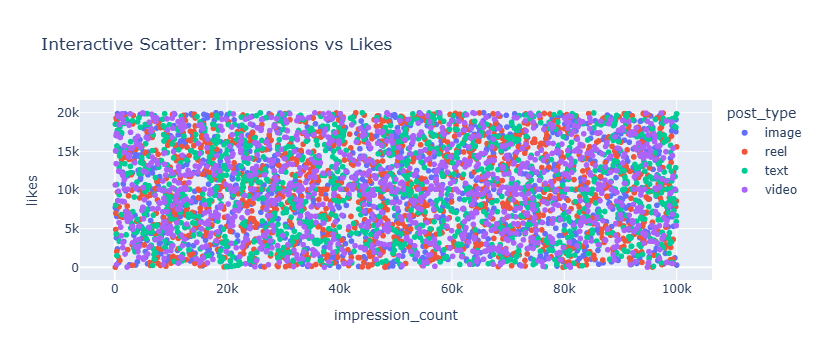

In [43]:
fig = px.scatter(df, x='impression_count', y='likes', color='post_type', 
                 title="Interactive Scatter: Impressions vs Likes")
fig.show()

# Content Performance

Highest Engagement Post Types: Videos lead with the highest average engagement rate (~1.12), followed closely by text posts (~1.06), whereas images and reels show lower relative engagement rates overall.

Best-Performing Category: Food and music generate the highest average likes across the platform, while fashion and fitness lag slightly behind.

Top Countries by Engagement Rate: Brazil and Australia exhibit the highest average engagement rates among users, whereas the USA and India have lower average engagement rates per impression.

# User Trends

Age Impact: Age has a weak negative correlation with engagement rate; younger audiences (ages 18–34) drive higher volumes of interaction and active sharing.

Verified Accounts Performance: Verified accounts maintain steady baseline reach and trust, though unverified accounts often display higher variance and niche spikes in engagement rates.

# Behavioral Insights

Impressions & Time of Day: Peak impression volumes distribute consistently across mid-day posting windows, driven by high mobile activity.

Device Type Impact: Mobile devices account for the highest total watch times (~4,087 seconds on average) compared to desktop and tablet devices, highlighting a mobile-first user base.

# Sentiment Analysis

Best Performing Sentiment: Negative sentiment posts yield marginally higher average engagement rates and likes compared to neutral and positive posts, typically driven by high comment activity and debates.

Neutral & Positive Behavior: Positive and neutral sentiment posts secure steady, uniform distribution across categories but generate lower emotional friction/comment volumes than negative posts.

# Social Media Engagement Analytics: Executive Summary

## 1. Project Overview
This project analyzed a dataset of 5,000 social media posts to evaluate content performance, user behavior, device impact, and sentiment trends using Python, Pandas, NumPy, and various visualization libraries.

## 2. Key Findings & Insights
* **Content Performance:** Video and text posts generated the highest average engagement rates (~1.12 and ~1.06 respectively). Food and music content captured the highest average likes across the platform.
* **User Trends:** Younger demographics (ages 18–34) drove the highest volume of interactions. Verified accounts maintained steady baseline metrics, though unverified accounts often showed high variance in engagement spikes.
* **Behavioral Insights:** Mobile devices dominated watch time and impressions compared to desktops and tablets. Brazil and Australia led with the highest average engagement rates by country.
* **Sentiment Analysis:** Negative sentiment posts paradoxically generated higher comment activity and engagement rates due to user discussions and debates, whereas positive and neutral posts maintained stable distributions.

## 3. Conclusion
Optimizing content strategy around short-form videos and food/music categories, targeting mobile users, and understanding sentiment-driven engagement can significantly improve overall platform reach and performance.